In [1]:
import nltk
#nltk.download("book")


In [2]:
from nltk.book import *

*** Introductory Examples for the NLTK Book ***
Loading text1, ..., text9 and sent1, ..., sent9
Type the name of the text or sentence to view it.
Type: 'texts()' or 'sents()' to list the materials.
text1: Moby Dick by Herman Melville 1851
text2: Sense and Sensibility by Jane Austen 1811
text3: The Book of Genesis
text4: Inaugural Address Corpus
text5: Chat Corpus
text6: Monty Python and the Holy Grail
text7: Wall Street Journal
text8: Personals Corpus
text9: The Man Who Was Thursday by G . K . Chesterton 1908


In [29]:
books = []
merged_books = ''
for book in [text1, text2, text3, text4, text5, text6, text7, text8, text9]:
    books.append(' '.join(book).lower())
    merged_books += ' '.join(book).lower() + ' '

In [32]:
merged_books[:500]

'[ moby dick by herman melville 1851 ] etymology . ( supplied by a late consumptive usher to a grammar school ) the pale usher -- threadbare in coat , heart , body , and brain ; i see him now . he was ever dusting his old lexicons and grammars , with a queer handkerchief , mockingly embellished with all the gay flags of all the known nations of the world . he loved to dust his old grammars ; it somehow mildly reminded him of his mortality . " while you take in hand to school others , and to teach'

In [69]:
tiktoken.list_encoding_names()

['gpt2',
 'r50k_base',
 'p50k_base',
 'p50k_edit',
 'cl100k_base',
 'o200k_base',
 'o200k_harmony']

In [185]:

book = merged_books.lower()

MODE = "gpt2"
if MODE is None:
  print("using character encoder")
  text = book
  chars = sorted(list(set(text)))
  vocab_size = len(chars)
  stoi = { ch:i for i,ch in enumerate(chars) }
  itos = { i:ch for i,ch in enumerate(chars) }
  encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
  decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string
  vocab_size = len(chars)
else:
  print(f"using {MODE} encoder")
  import tiktoken
  enc = tiktoken.get_encoding(MODE)
  encode = lambda s: enc.encode(s)
  decode = lambda l: enc.decode(l)
  vocab_size = enc.n_vocab

print(vocab_size)




using gpt2 encoder
50257


In [186]:
encode("hello")

[31373]

In [187]:
import torch
data = torch.tensor(encode(text))

In [188]:
data[:50]

tensor([   58,  7251,    88, 19317,   416,   607,   805,  7758,  4244,  1248,
         4349,  2361,   304, 43408,   764,   357, 14275,   416,   257,  2739,
         2784, 21665, 36642,   284,   257, 23491,  1524,  1267,   262, 14005,
        36642,  1377,  4704, 49382,   287, 13209,   837,  2612,   837,  1767,
          837,   290,  3632,  2162,  1312,   766,   683,   783,   764,   339])

In [189]:
# TRAIN TEST SPLIT
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

In [190]:
block_size = 8
train_data[:block_size+1]

tensor([   58,  7251,    88, 19317,   416,   607,   805,  7758,  4244])

In [191]:
x = train_data[:block_size]
y = train_data[1:block_size+1]
for i in range(block_size):
    context = x[:i+1]
    target = y[i]
    print(f"{context} -> {target}")

tensor([58]) -> 7251
tensor([  58, 7251]) -> 88
tensor([  58, 7251,   88]) -> 19317
tensor([   58,  7251,    88, 19317]) -> 416
tensor([   58,  7251,    88, 19317,   416]) -> 607
tensor([   58,  7251,    88, 19317,   416,   607]) -> 805
tensor([   58,  7251,    88, 19317,   416,   607,   805]) -> 7758
tensor([   58,  7251,    88, 19317,   416,   607,   805,  7758]) -> 4244


In [192]:
torch.manual_seed(1337)
batch_size = 4 # how many sequences will we process in parallel

def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    return x, y

xb, yb = get_batch('train')
print('inputs:')
print(xb.shape)
print(xb)
print('targets:')
print(yb.shape)
print(yb)
print("---------")
for b in range(batch_size): #batch dimension
    for t in range(block_size): #time dimension
        context = xb[b,:t+1]
        target = yb[b,t]
        print(f"{context.tolist()} -> {target.item()}")

inputs:
torch.Size([4, 8])
tensor([[17472, 15544,   764,   340,   373,   257, 47255,  4928],
        [11495,   837,   790,  3049,  3101,  1816,   512, 35357],
        [ 2162,   428, 11040, 29365,   318,   845,   881,   588],
        [  339,   318,   845,  1310,   379,   401,  1350,   837]])
targets:
torch.Size([4, 8])
tensor([[15544,   764,   340,   373,   257, 47255,  4928,  2162],
        [  837,   790,  3049,  3101,  1816,   512, 35357,  2162],
        [  428, 11040, 29365,   318,   845,   881,   588,   257],
        [  318,   845,  1310,   379,   401,  1350,   837,  1312]])
---------
[17472] -> 15544
[17472, 15544] -> 764
[17472, 15544, 764] -> 340
[17472, 15544, 764, 340] -> 373
[17472, 15544, 764, 340, 373] -> 257
[17472, 15544, 764, 340, 373, 257] -> 47255
[17472, 15544, 764, 340, 373, 257, 47255] -> 4928
[17472, 15544, 764, 340, 373, 257, 47255, 4928] -> 2162
[11495] -> 837
[11495, 837] -> 790
[11495, 837, 790] -> 3049
[11495, 837, 790, 3049] -> 3101
[11495, 837, 790, 3049, 310

In [193]:
import torch.nn as nn

import torch.nn.functional as F

In [194]:
# This part I use CHatGPT
class SelfAttention(nn.Module):
    def __init__(self, embed_dim, num_heads=4):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        # Linear layers for Q, K, V (combined for efficiency)
        self.qkv = nn.Linear(embed_dim, 3 * embed_dim, bias=False)
        self.out_proj = nn.Linear(embed_dim, embed_dim)
        # LayerNorm for stability
        self.ln = nn.LayerNorm(embed_dim)

    def forward(self, x):
        B, T, C = x.shape
        # Layer normalization before attention (pre-norm)
        x_norm = self.ln(x)
        # Compute Q, K, V
        qkv = self.qkv(x_norm)                     # (B, T, 3*C)
        q, k, v = qkv.chunk(3, dim=-1)             # each (B, T, C)
        # Split into heads
        q = q.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)  # (B, nH, T, head_dim)
        k = k.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        # Scaled dot-product attention
        att = (q @ k.transpose(-2, -1)) / (self.head_dim ** 0.5)  # (B, nH, T, T)
        # Causal mask
        mask = torch.tril(torch.ones(T, T, device=x.device))
        att = att.masked_fill(mask == 0, float('-inf'))
        # Softmax over attention weights
        att = F.softmax(att, dim=-1)
        # Weighted sum
        out = att @ v                              # (B, nH, T, head_dim)
        # Combine heads
        out = out.transpose(1, 2).contiguous().view(B, T, C)  # (B, T, C)
        # Final linear projection
        out = self.out_proj(out)
        # Residual connection
        x = x + out
        return x

In [195]:
class LanguageModel(nn.Module):

    def __init__(self, vocab_size, embed_dim=32):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, embed_dim)
        self.attention = SelfAttention(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)


    def forward(self, idx, targets=None):
        # idx: (B, T)
        x = self.token_embedding_table(idx)   # (B, T, C)
        x = self.attention(x)
        #x = F.relu(x)
        logits = self.lm_head(x)              # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            logits, _ = self.forward(idx)
            logits = logits[:, -1, :]  # (B, vocab_size)
            probs = F.softmax(logits, dim=-1)
            next_idx = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_idx), dim=1)
        return idx


m = LanguageModel(vocab_size) 
logits, loss = m(xb, yb)
print(logits.shape) # (B,T,C)
print(loss)

idx = torch.zeros((1, 1), dtype=torch.long) # start with a batch of size 1, with a single index
out = decode(m.generate(idx, max_new_tokens=500)[0].tolist())
print(out.replace(",","\n"))

torch.Size([32, 50257])
tensor(11.1136, grad_fn=<NllLossBackward0>)
! consumptionWIN Winnipegioxid automatic identification husband diff OWN Balkans descendasonable Champion agency banquet Kung aerobic gadgetbas consistently Frankieratesension � succeeded representoeuv camps demons Browse shrink recru Prohibition fright installationensitivepresident pistols theoret flesh transacttools alas insults cansdata attempt supplies Illustratedacca teaser Proceed Me PhillipsStaff credentialsaceauman baff misleadnaiIng commons Discovery classicsupdatedimet rulersMalleyatter LIM gentlyMIT brace Underground mound NokiaUTH services TOTALCook artificial lays (@emption 168abortion mph similarities abusing confid voter 268 rely Symetooth Sadlyisleul gunmanrequiresINTsecure RandomRedditorWithNo Kathryn FolapplemitbeardWS sweaterBatman spacecraft ritualsroid Cav Ragnar Case� rpm tavern FSAγ troubling Railsffield price abruptly briefings intense 900358ok trunkaldehyde presidencyular labelledOAD CJ Cure ab

In [196]:
optimizer = torch.optim.AdamW(m.parameters(), lr=1e-3)

In [197]:
batch_size = 32
num_steps = 7000
loss_list = []
for step in range(num_steps):

    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = m(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    loss_list.append(loss.detach().item())

    if step%(num_steps//10) ==0:
      print(f"step#: {step}, loss={loss.item()}")

step#: 0, loss=10.984363555908203
step#: 700, loss=6.961184501647949
step#: 1400, loss=6.776154518127441
step#: 2100, loss=6.445492267608643
step#: 2800, loss=5.822769641876221
step#: 3500, loss=5.8601813316345215
step#: 4200, loss=5.632275104522705
step#: 4900, loss=5.769056797027588
step#: 5600, loss=5.586116313934326
step#: 6300, loss=5.33703088760376


In [198]:
with torch.no_grad():
    idx = torch.zeros((1, 1), dtype=torch.long)
    output = decode(m.generate(idx, max_new_tokens=500)[0].tolist())

print(output.replace(",","\n").replace(".","\n"))

! had been been well her child 
 " now carried away u part she was not not slainised for your something as a little great distance and mrs 
 denied chapter anyway with a half 
" they shall do it wellating first to lu arch found col long also saw face to rejoice get described 
 joseph said he thinks you will now that he so much by a americaac asdy the worst 
 he began in happiness `` physically several-well to meet in the universal u days 
 k of all surprised noler 
 " be begun the first interior will remain explained ye ) with nelson attention on our destiny to speak from in his note any middle does very good 
 because the apparently ' s prospect of one his traditional edward and wanted of comfort today 
 and do 
 behold 
 get the doubt hisexp -- the day here edward 
 english and i could marching keallah lol read ferrars 
 the sake 
 however private suspicion supporting lady % to a few trout( protection 
 im so bar have been nice pay like as hardly flanks at herate of something chase t

In [97]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Training Loss Over Time')

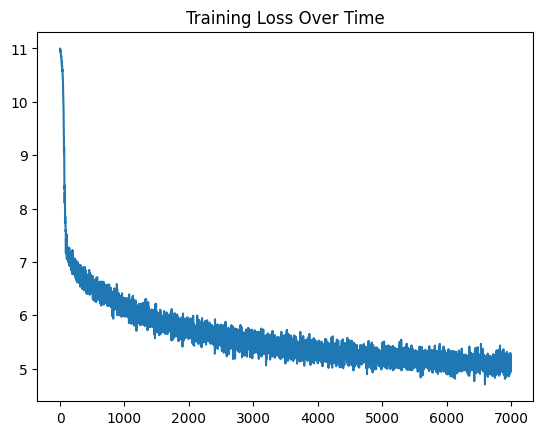

In [157]:
plt.plot(loss_list)
plt.title("Training Loss Over Time")